## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(215)
raw = pd.read_csv("DataSet.csv")
df  = pd.read_csv("CleanedDataSet.csv")
print(raw.shape, df.shape)

(1698, 14) (1698, 29)


## Cleaning

In [2]:
if "Lead Star" not in df.columns:
    id_cols = ["Movie Name", "Release Period", "Lead Star", "Director",
               "Music Director", "Genre"]
    df = df.merge(raw[id_cols], on="Movie Name", how="left", validate="one_to_one")
assert df["Lead Star"].notna().all()

chk = raw[["Movie Name", "Budget(INR)", "Revenue(INR)", "Number of Screens",
           "Release Period"]].merge(
      df [["Movie Name", "Budget", "Revenue", "Number of Screens",
           "Holiday"]],
      on="Movie Name", suffixes=("_raw", "_clean"))
for c_raw, c_clean in [("Budget(INR)", "Budget"), ("Revenue(INR)", "Revenue")]:
    assert (chk[c_raw] == chk[c_clean]).all(), f"mismatch on {c_raw}"
assert (chk["Number of Screens_raw"] == chk["Number of Screens_clean"]).all(), "mismatch on screens"
assert ((chk["Release Period"] == "Holiday") == chk["Holiday"]).all()
print("all consistency checks passed")

df["log_budget"]  = np.log(df["Budget"])
df["log_revenue"] = np.log(df["Revenue"])
df["log_screens"] = np.log(df["Number of Screens"])

all consistency checks passed


## Description

In [3]:
cols = ["Budget", "Revenue", "ROI", "log_budget", "log_revenue"]
print(df[cols].describe().T[["mean", "50%", "min", "max"]].round(1))
print("skew:", df[cols].skew().round(3).to_dict())
print("films below budget:", (df["Revenue"] < df["Budget"]).sum())

                    mean         50%       min           max
Budget       150123218.5  55000000.0  325000.0  2.100000e+09
Revenue      237806127.4  12500000.0    7250.0  8.016120e+09
ROI                  0.8         0.3       0.0  8.400000e+00
log_budget          17.7        17.8      12.7  2.150000e+01
log_revenue         16.4        16.3       8.9  2.280000e+01
skew: {'Budget': 3.304, 'Revenue': 5.82, 'ROI': 2.226, 'log_budget': -0.301, 'log_revenue': -0.006}
films below budget: 1225


**📌 Inference (Step 2):** Step 2 showed us why the log scale is necessary: revenue has skew 5.82 while log revenue has skew 0.006, and the mean (23.8 crore) is 19 times the median (1.25 crore), so the average Bollywood film does not exist. we also found that 1,225 of 1,698 films (72%) never recover their budget, which tells us profits live almost entirely in the tail and even budgets are skewed (3.30) before any output is measured.

## Graphical Representation

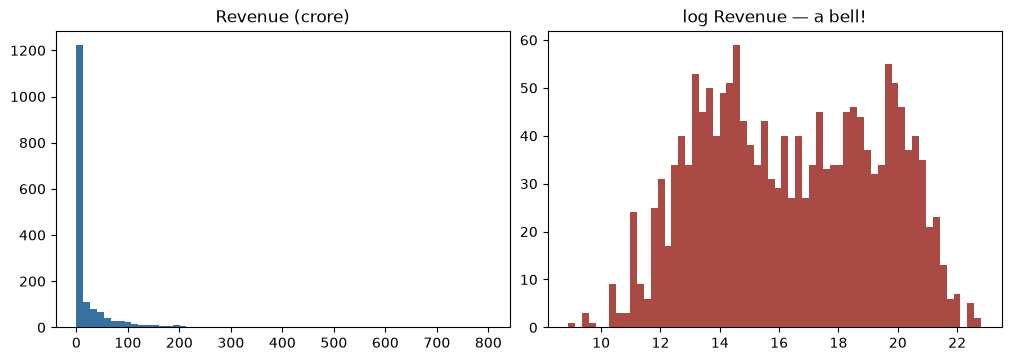

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
ax[0].hist(df["Revenue"]/1e7, bins=60, color="#3771a0"); ax[0].set_title("Revenue (crore)")
ax[1].hist(df["log_revenue"], bins=60, color="#aa4a44"); ax[1].set_title("log Revenue — a bell!")
plt.show()

**📌 Inference (Step 3):** Step 3 made the same point visually: on the raw scale the histogram is one spike with an invisible tail, but on the log scale a near perfect bell appears, which told us before any fitting that a normal distribution applied to log revenue is the right candidate.

## χ² contest: six taught candidates on Revenue
**Uniform, Normal, Exponential, Chi-square, Student-t, and Normal-on-log.**

In [5]:
rev = df["Revenue"].values.astype(float)

def chisq_gof(data, name, params, m, k=10):
    """χ² GOF: bin by the fitted model's own deciles; m = estimated parameters."""
    d = getattr(stats, name)
    edges = d.ppf(np.linspace(0, 1, k + 1), *params)
    edges[0], edges[-1] = -np.inf, np.inf
    obs = np.histogram(data, bins=edges)[0]
    exp = np.full(k, len(data) / k)
    stat, p = stats.chisquare(obs, exp, ddof=m)
    return stat, p, k - 1 - m, obs

cands = []
p_u = stats.uniform.fit(rev)
cands.append(("Uniform ", np.sum(stats.uniform.logpdf(rev, *p_u)), "uniform", p_u, 2))
p_n = stats.norm.fit(rev)
cands.append(("Normal ", np.sum(stats.norm.logpdf(rev, *p_n)), "norm", p_n, 2))
p_e = stats.expon.fit(rev, floc=0)
cands.append(("Exponential", np.sum(stats.expon.logpdf(rev, *p_e)), "expon", p_e, 1))
p_c = stats.chi2.fit(rev, floc=0)
cands.append(("Chi-square family", np.sum(stats.chi2.logpdf(rev, *p_c)), "chi2", p_c, 2))
p_t = stats.t.fit(rev)
cands.append(("t-distribution", np.sum(stats.t.logpdf(rev, *p_t)), "t", p_t, 3))
ly  = np.log(rev); mu, sd = ly.mean(), ly.std(ddof=0)
ll_ln = np.sum(stats.norm.logpdf(ly, mu, sd)) - ly.sum()
cands.append(("Normal on log = lognormal", ll_ln, "lognorm", (sd, 0, np.exp(mu)), 2))

for label, ll, nm, par, m in cands:
    chi2, p, dfree, obs = chisq_gof(rev, nm, par, m)
    print(f"{label:28s} LL={ll:10.0f}  chi2={chi2:8.1f} (df={dfree})  bins={obs}")
print("fitted dials: t df =", round(p_t[0], 2), "| chi2 df =", round(p_c[0], 2))

Uniform                      LL=    -38722  chi2= 12492.7 (df=7)  bins=[1549   95   32    8    7    0    1    4    1    1]
Normal                       LL=    -36767  chi2=  6217.7 (df=7)  bins=[   0    0    0 1130  191   91   76   53   51  106]
Exponential                  LL=    -34447  chi2=  4071.0 (df=8)  bins=[945 122  69  70  54  49  37  53  87 212]
Chi-square family            LL=    -32307  chi2=   567.2 (df=7)  bins=[ 21 375 320 172 140 115 129 111 148 167]
t-distribution               LL=    -33479  chi2=  1895.6 (df=6)  bins=[  0   0   0   0   0 356 258 234 404 446]
Normal on log = lognormal    LL=    -32140  chi2=   135.5 (df=7)  bins=[180 241 196 135 108 106 124 169 242 197]
fitted dials: t df = 0.28 | chi2 df = 0.5


**See WHERE each curve fails** — fitted curves drawn on the data:

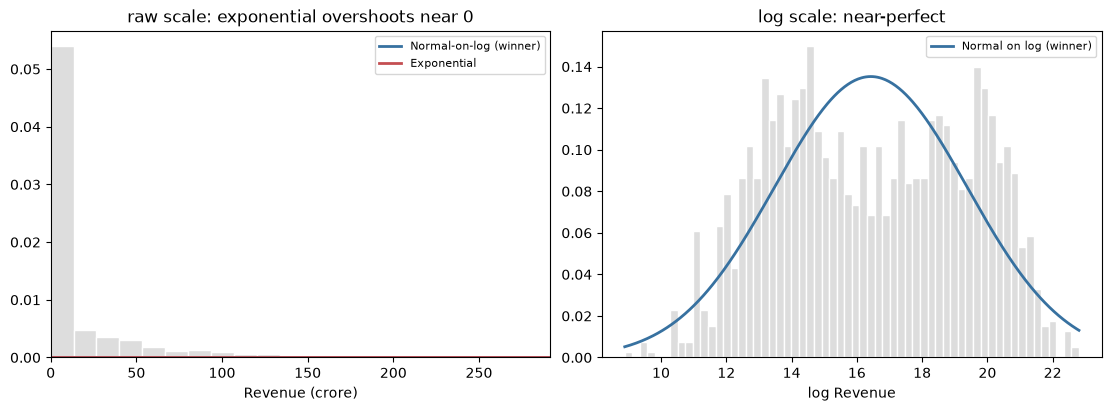

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ax[0].hist(rev/1e7, bins=60, density=True, color="#dddddd", edgecolor="white")
xs = np.linspace(0, np.quantile(rev, 0.99), 400)
ax[0].plot(xs/1e7, stats.lognorm.pdf(xs, sd, 0, np.exp(mu)), color="#3771a0",
           lw=2, label="Normal-on-log (winner)")
ax[0].plot(xs/1e7, stats.expon.pdf(xs, *p_e), color="#c44e52", lw=2, label="Exponential")
ax[0].set_xlim(0, np.quantile(rev, 0.99)/1e7); ax[0].set_xlabel("Revenue (crore)")
ax[0].set_title("raw scale: exponential overshoots near 0"); ax[0].legend(fontsize=8)
ax[1].hist(np.log(rev), bins=60, density=True, color="#dddddd", edgecolor="white")
xs2 = np.linspace(np.log(rev).min(), np.log(rev).max(), 400)
ax[1].plot(xs2, stats.norm.pdf(xs2, mu, sd), color="#3771a0", lw=2, label="Normal on log (winner)")
ax[1].set_xlabel("log Revenue"); ax[1].set_title("log scale: near-perfect")
ax[1].legend(fontsize=8); plt.show()

**📌 Inference (Step 4):** In step 4 we fitted six taught families by MLE and scored each with the chi square test on the fitted model's own deciles. The normal on log revenue won clearly (chi square 135.5 against 6,218 for the raw normal, 4,071 for the exponential and 12,493 for the uniform), the bin counts showed exactly where the losers fail, and since at n = 1698 even the winner is formally rejectable we use chi square to rank models rather than to crown a truth.

## Same χ² contest for ROI

In [7]:
roi = df["ROI"].values.astype(float)
cands = []
p_u = stats.uniform.fit(roi)
cands.append(("Uniform", np.sum(stats.uniform.logpdf(roi, *p_u)), "uniform", p_u, 2))
p_n = stats.norm.fit(roi)
cands.append(("Normal", np.sum(stats.norm.logpdf(roi, *p_n)), "norm", p_n, 2))
p_t = stats.t.fit(roi)
cands.append(("Student-t", np.sum(stats.t.logpdf(roi, *p_t)), "t", p_t, 3))
p_e = stats.expon.fit(roi, floc=0)
cands.append(("Exponential", np.sum(stats.expon.logpdf(roi, *p_e)), "expon", p_e, 1))
p_c = stats.chi2.fit(roi, floc=0)
cands.append(("Chi-square family", np.sum(stats.chi2.logpdf(roi, *p_c)), "chi2", p_c, 2))
ly_r = np.log(roi); mu_r, sd_r = ly_r.mean(), ly_r.std(ddof=0)
ll_ln_r = np.sum(stats.norm.logpdf(ly_r, mu_r, sd_r)) - ly_r.sum()
cands.append(("Normal on log(ROI)", ll_ln_r, "lognorm", (sd_r, 0, np.exp(mu_r)), 2))
for label, ll, nm, par, m in cands:
    chi2, p, dfree, obs = chisq_gof(roi, nm, par, m)
    print(f"{label:24s} LL={ll:9.1f}  chi2={chi2:8.1f} (df={dfree})  bins={obs}")
print("fitted dials: t df =", round(p_t[0], 2), "| chi2 df =", round(p_c[0], 2))

Uniform                  LL=  -3610.9  chi2=  6721.2 (df=7)  bins=[1152  277  139   72   32   11    8    5    1    1]
Normal                   LL=  -2502.3  chi2=  2594.6 (df=7)  bins=[  0   0 767 223 144 115  93  87  87 182]
Student-t                LL=  -2088.9  chi2=  1601.4 (df=6)  bins=[  0   0  30 466 175 113  86 115 247 466]
Exponential              LL=  -1307.9  chi2=   577.5 (df=8)  bins=[424 243 136 120  82  97 105 114 147 230]
Chi-square family        LL=  -1144.3  chi2=   154.5 (df=7)  bins=[127 290 220 161 137 107 137 151 168 200]
Normal on log(ROI)       LL=  -1143.4  chi2=   103.0 (df=7)  bins=[188 199 157 147 117 138 131 206 263 152]
fitted dials: t df = 0.85 | chi2 df = 1.23


**📌 Inference (Step 4b):** Step 4b repeated the contest for ROI and the normal on log ROI won again (103 vs 2,595), while the exponential improved a lot compared to revenue (577 vs 4,071), which tells us returns per rupee have a much lighter tail than rupee totals. On log likelihood the chi square family was only 0.9 points behind, but chi square separated them clearly, so we trusted both scores together.

## MoM vs MLE

In [8]:
m_, v_ = rev.mean(), rev.var()
s_mom  = np.sqrt(np.log1p(v_/m_**2))
mu_mom = np.log(m_) - s_mom**2/2
ll_mom = np.sum(stats.lognorm.logpdf(rev, s_mom, 0, np.exp(mu_mom)))
print("MoM lognorm LL =", round(ll_mom), " vs MLE -32,140  (raw moments destroyed by the tail)")
print("note: on the LOG scale MoM = MLE (for a Normal both use sample mean/sd)")

MoM lognorm LL = -35105  vs MLE -32,140  (raw moments destroyed by the tail)
note: on the LOG scale MoM = MLE (for a Normal both use sample mean/sd)


**📌 Inference (Step 5):** In step 5 we matched raw moments and got a far worse fit (LL minus 35,105 vs minus 32,140) because the 801 crore blockbuster destroys the sample mean and variance. On the log scale method of moments and MLE give the identical answer, which shows the problem was the scale of the moments, not the method itself, so under heavy tails we prefer likelihood.

## Luck-tube QQ + log10 histogram + simulation χ² p

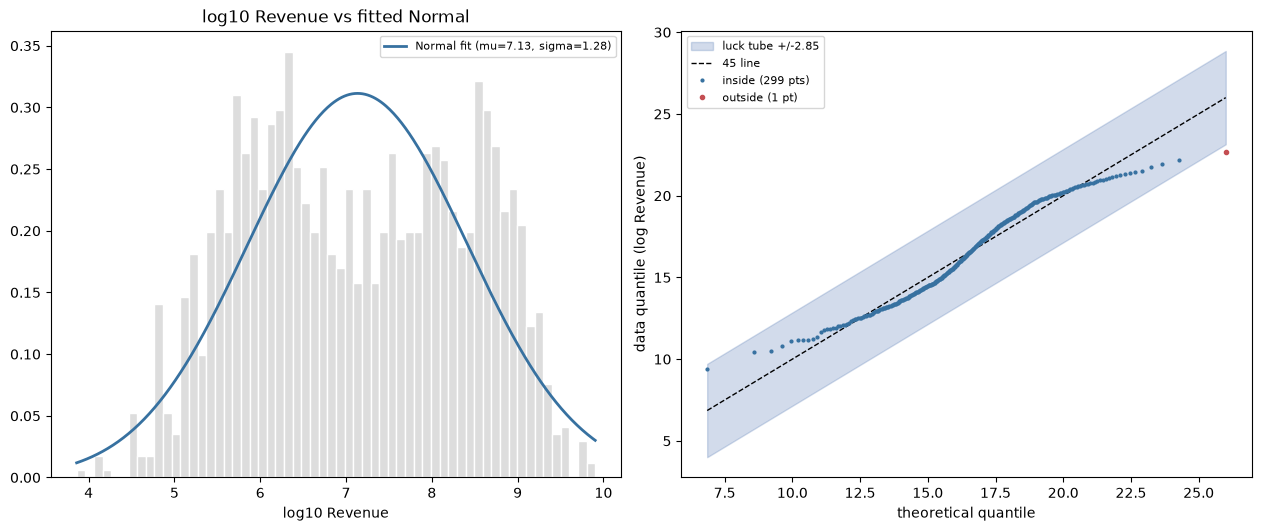

luck tube +/- 2.85 | real worst dev: 3.33


In [9]:
ly_rev = np.log(rev)
mu, sd = ly_rev.mean(), ly_rev.std(ddof=0)
probs = np.linspace(1/(len(rev)+1), len(rev)/(len(rev)+1), 300)
emp   = np.quantile(ly_rev, probs)
theo  = stats.norm.ppf(probs, mu, sd)

sims  = np.sort(rng.normal(mu, sd, size=(400, len(rev))), axis=1)
idx   = (probs*(len(rev)+1) - 1).clip(0, len(rev)-1).astype(int)
D_luck = np.max(np.abs(sims[:, idx] - theo), axis=1)
D95    = np.percentile(D_luck, 95)
D_real = np.max(np.abs(emp - theo))
outside = np.abs(emp - theo) > D95

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), constrained_layout=True)
l10 = np.log10(rev); mu10, sd10 = l10.mean(), l10.std(ddof=0)
xs10 = np.linspace(l10.min(), l10.max(), 400)
axes[0].hist(l10, bins=60, density=True, color="#dddddd", edgecolor="white")
axes[0].plot(xs10, stats.norm.pdf(xs10, mu10, sd10), color="#3771a0", lw=2,
             label=f"Normal fit (mu={mu10:.2f}, sigma={sd10:.2f})")
axes[0].set_xlabel("log10 Revenue"); axes[0].set_title("log10 Revenue vs fitted Normal")
axes[0].legend(fontsize=8)
ax = axes[1]
ax.fill_between(theo, theo-D95, theo+D95, alpha=.25, color="#4c72b0",
                label=f"luck tube +/-{D95:.2f}")
ax.plot(theo, theo, "k--", lw=1, label="45 line")
ax.plot(theo[~outside], emp[~outside], ".", ms=4, color="#3771a0",
        label=f"inside ({(~outside).sum()} pts)")
ax.plot(theo[outside], emp[outside], ".", ms=6, color="#c44e52",
        label=f"outside ({outside.sum()} pt)")
ax.set_xlabel("theoretical quantile"); ax.set_ylabel("data quantile (log Revenue)")
ax.legend(fontsize=8); plt.show()
print("luck tube +/-", round(D95, 2), "| real worst dev:", round(D_real, 2))

In [10]:
params   = stats.lognorm.fit(rev, floc=0)
obs_chi2 = chisq_gof(rev, "lognorm", params, 2)[0]
hits     = 0
for _ in range(400):
    sim      = stats.lognorm.rvs(*params, size=len(rev), random_state=rng)
    p2       = stats.lognorm.fit(sim, floc=0)
    sim_chi2 = chisq_gof(sim, "lognorm", p2, 2)[0]
    hits    += (sim_chi2 >= obs_chi2)
print("observed chi2 =", round(obs_chi2, 1),
      "| simulation-based chi2 p =", (hits + 1) / 401)

observed chi2 = 135.5 | simulation-based chi2 p = 0.0024937655860349127


**📌 Inference (Step 6):** Step 6 audited the winner two ways. The luck tube built from 400 fake industries kept 299 of 300 quantile points inside, with only the richest film escaping below the tube, meaning the model's tail allows bigger blockbusters than reality. The simulation test gave chi square p = 0.0025, so at the alpha = 0.05 level the lognormal is formally rejected even though the visual fit is excellent, and because we fitted the parameters from the same data we calibrated the p value by simulation instead of using the textbook table.

## Simulation

In [11]:
boots = np.array([stats.lognorm.fit(stats.lognorm.rvs(*params, size=len(rev), random_state=rng),
                                    floc=0) for _ in range(2_000)])
ci = np.percentile(boots, [2.5, 97.5], axis=0)

print("95% CI  s:", ci[:, 0].round(3), "  scale:", ci[:, 2].round(0))
print("SE(s) from simulation:", round(boots[:, 0].std(ddof=1), 4))

95% CI  s: [2.853 3.051]   scale: [11860384. 15616963.]
SE(s) from simulation: 0.0514


### STEP 7b — how many resamples? (convergence demo)
More resamples do NOT move the estimate  they only steady the SE/CI measurement:

In [12]:
print('B (resamples) |  SE(s)  | 95% CI of s')
for B in [500, 1000, 3000, 10000]:
    bs = np.array([stats.lognorm.fit(stats.lognorm.rvs(*params, size=len(rev), random_state=rng),
                                     floc=0) for _ in range(B)])
    s_b = bs[:, 0]
    lo, hi = np.percentile(s_b, [2.5, 97.5])
    print(f'{B:12d} | {s_b.std(ddof=1):.4f} | [{lo:.3f}, {hi:.3f}]')
print('the full-data MLE s =', round(params[0], 4), ' never moves — resamples only re-measure it')

B (resamples) |  SE(s)  | 95% CI of s
         500 | 0.0493 | [2.846, 3.038]


        1000 | 0.0524 | [2.852, 3.052]


        3000 | 0.0513 | [2.850, 3.050]


       10000 | 0.0512 | [2.850, 3.050]
the full-data MLE s = 2.9503  never moves — resamples only re-measure it


**📌 Inference (Step 7):** Step 7 attached uncertainty by simulation: 2,000 resamples put s between 2.85 and 3.05 with SE 0.051, and the convergence test from 500 to 10,000 resamples showed the interval barely moves, so the shape of the fit is a stable feature of this industry. Resampling cannot create information, it only measures the uncertainty more precisely.

## Scale-bin tests (label shuffling): H1/H2 per `Scale_Bin`

Same categorization as the regression and hypothesis notebooks: `Scale_Bin = pd.cut(Movie_Scale, bins=range(0, 11))`, i.e. the (1,2] … (9,10] bins.

In [13]:
df["Scale_Bin"] = pd.cut(df["Movie_Scale"], bins=range(0, 11)).cat.remove_unused_categories()  # identical to 4./5.

def band_test(sub, flag, metric="log_revenue", B=10_000, B2=2_000):
    """Within one scale bin: gap in the metric, label-shuffle p, simulation 95% CI."""
    x1 = sub.loc[sub[flag], metric].values
    x0 = sub.loc[~sub[flag], metric].values
    n1, n0 = len(x1), len(x0)
    if min(n1, n0) < 10:
        return {"diff": np.nan, "p": np.nan, "lo": np.nan, "hi": np.nan, "n1": n1, "n0": n0}
    obs  = x1.mean() - x0.mean()
    pool = np.concatenate([x1, x0])
    luck = np.empty(B)
    for b in range(B):
        p = rng.permutation(pool)
        luck[b] = p[:n1].mean() - p[n1:].mean()
    pv = (np.sum(luck >= obs) + 1) / (B + 1)
    bs = np.array([rng.choice(x1, n1, True).mean() - rng.choice(x0, n0, True).mean()
                   for _ in range(B2)])
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return {"diff": obs, "p": pv, "lo": lo, "hi": hi, "n1": n1, "n0": n0}

band_rows = []
for hyp, flag in [("H1 Holiday", "Holiday"),
                  ("H2 Franchise", "Franchise"),
                  ("H2 Remake", "Remake")]:
    for band, sub in df.groupby("Scale_Bin", observed=True):
        band_rows.append({"hyp": hyp, "scale_bin": str(band), **band_test(sub, flag)})
band_tbl = pd.DataFrame(band_rows)
print(band_tbl.dropna(subset=["diff"]).round(3))

             hyp scale_bin   diff      p     lo     hi   n1   n0
0     H1 Holiday    (1, 2]  0.024  0.469 -0.676  0.650   24   34
1     H1 Holiday    (2, 3]  0.223  0.170 -0.263  0.663   51   76
2     H1 Holiday    (3, 4] -0.046  0.583 -0.436  0.375   48   94
3     H1 Holiday    (4, 5] -0.017  0.538 -0.355  0.312   70  141
4     H1 Holiday    (5, 6]  0.245  0.073 -0.085  0.583   73  159
5     H1 Holiday    (6, 7] -0.206  0.878 -0.557  0.137   86  185
6     H1 Holiday    (7, 8]  0.027  0.419 -0.227  0.283  136  196
7     H1 Holiday    (8, 9]  0.206  0.023  0.010  0.412  104  150
8     H1 Holiday   (9, 10]  0.563  0.001  0.295  0.855   54   17
15  H2 Franchise    (7, 8]  0.428  0.045 -0.043  0.913   22  310
16  H2 Franchise    (8, 9]  0.222  0.066 -0.042  0.479   37  217
17  H2 Franchise   (9, 10]  0.273  0.057 -0.034  0.583   17   54
24     H2 Remake    (7, 8]  0.528  0.005  0.203  0.840   35  297
25     H2 Remake    (8, 9]  0.219  0.047 -0.014  0.443   48  206
26     H2 Remake   (9, 10

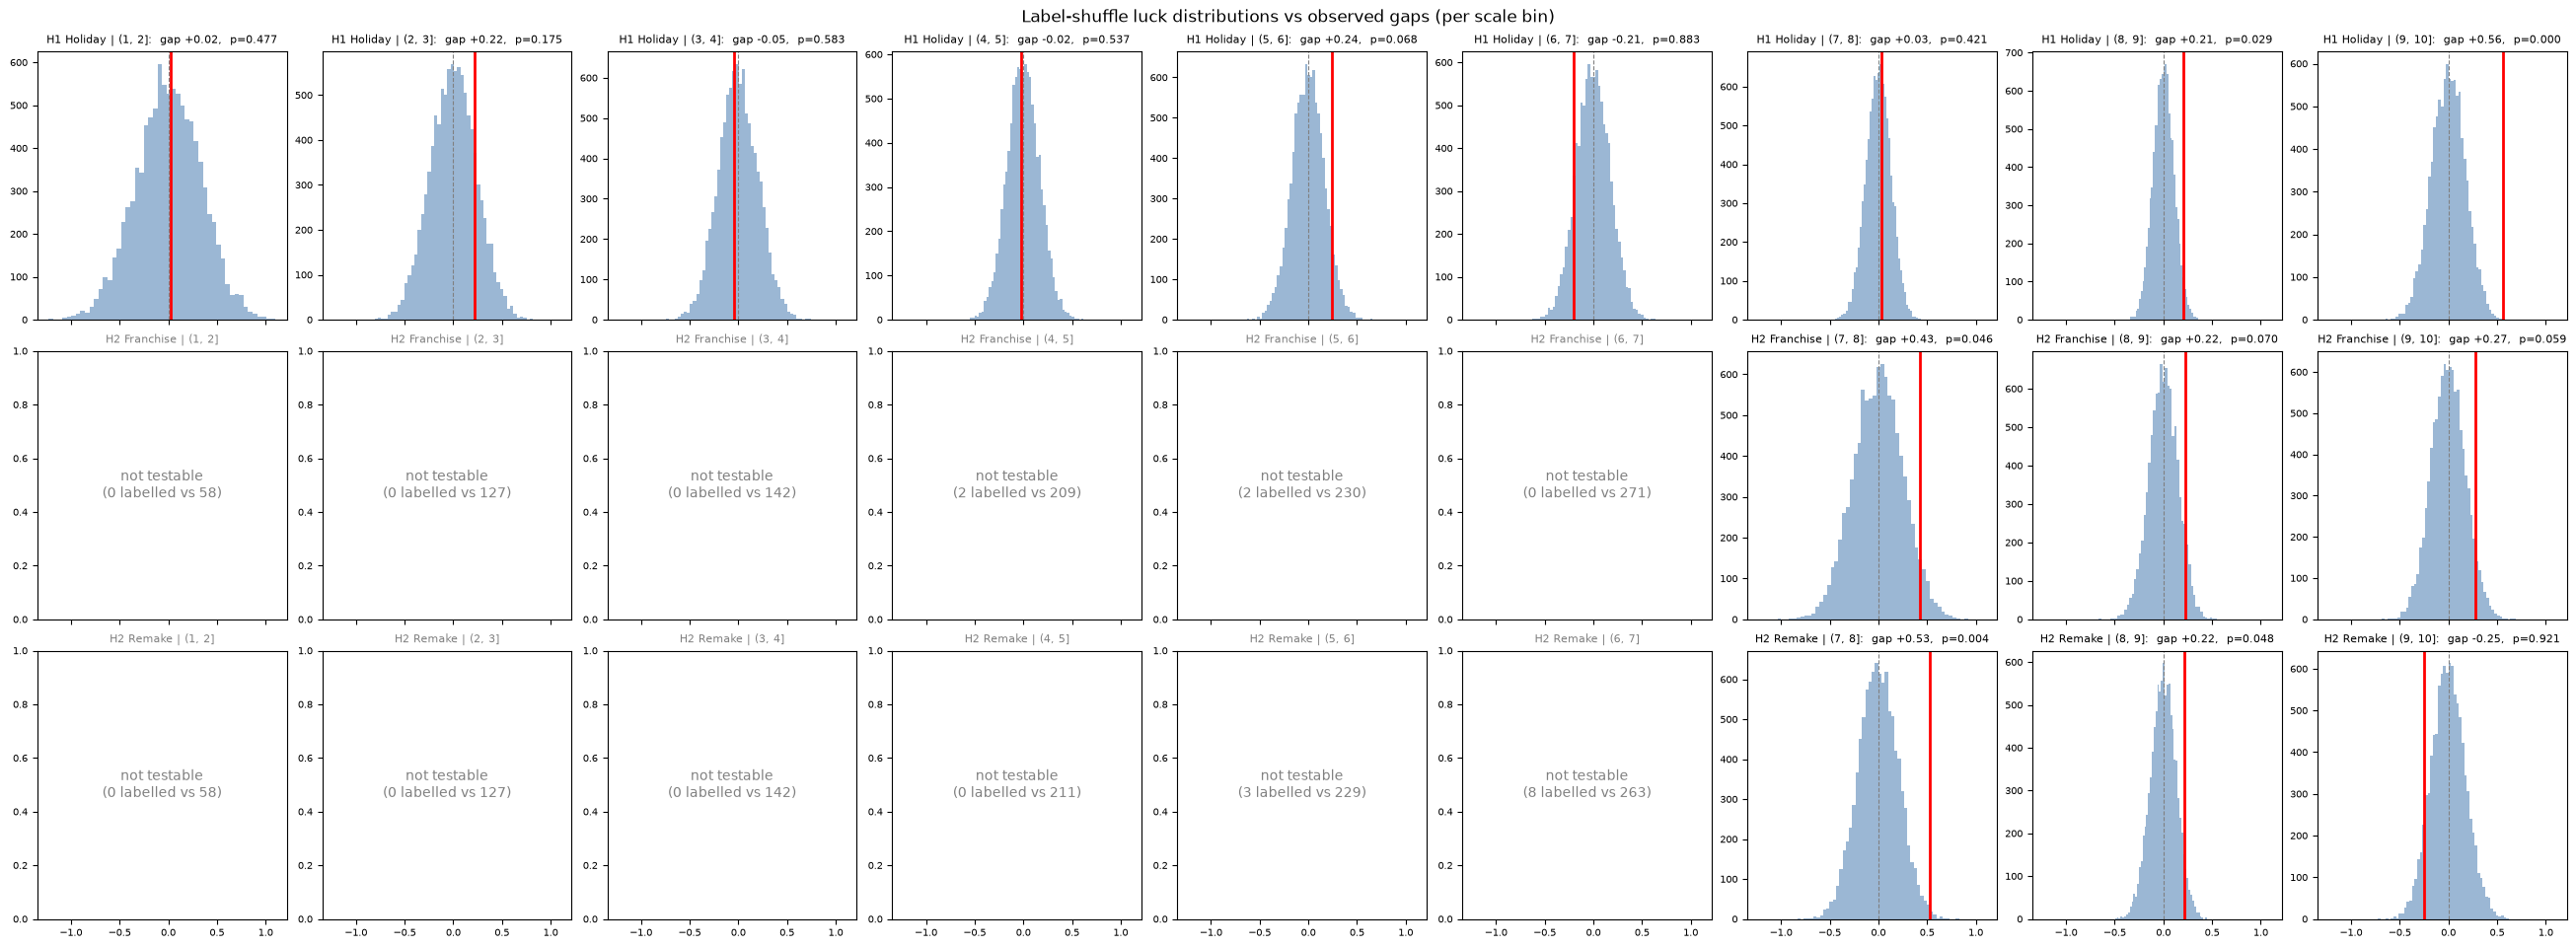

In [14]:
hyps  = [("H1 Holiday", "Holiday"),
         ("H2 Franchise", "Franchise"),
         ("H2 Remake", "Remake")]
bands = list(df["Scale_Bin"].cat.categories)
fig, axes = plt.subplots(3, 9, figsize=(26, 9.5), sharex=True, constrained_layout=True)
for i, (hyp, flag) in enumerate(hyps):
    for j, band in enumerate(bands):
        ax  = axes[i, j]
        sub = df[df["Scale_Bin"] == band]
        x1  = sub.loc[sub[flag], "log_revenue"].values
        x0  = sub.loc[~sub[flag], "log_revenue"].values
        n1, n0 = len(x1), len(x0)
        if min(n1, n0) < 10:
            ax.text(0.5, 0.5, f"not testable\n({n1} labelled vs {n0})", ha="center",
                    va="center", transform=ax.transAxes, fontsize=10, color="grey")
            ax.set_title(f"{hyp} | {str(band)}", fontsize=8, color="grey")
            continue
        pool = np.concatenate([x1, x0])
        obs  = x1.mean() - x0.mean()
        luck = np.array([(lambda p: p[:n1].mean() - p[n1:].mean())(rng.permutation(pool))
                         for _ in range(10_000)])
        p = (np.sum(luck >= obs) + 1) / 10_001
        ax.hist(luck, bins=50, color="#9bb7d4")
        ax.axvline(obs, color="red", lw=2); ax.axvline(0, color="grey", lw=0.8, ls="--")
        ax.set_title(f"{hyp} | {str(band)}:  gap {obs:+.2f},  p={p:.3f}", fontsize=8)
fig.suptitle("Label-shuffle luck distributions vs observed gaps (per scale bin)")
for ax in axes.flat:
    ax.tick_params(labelsize=7)
fig.savefig("histograms/shuffle_grid.png", dpi=120); plt.show()

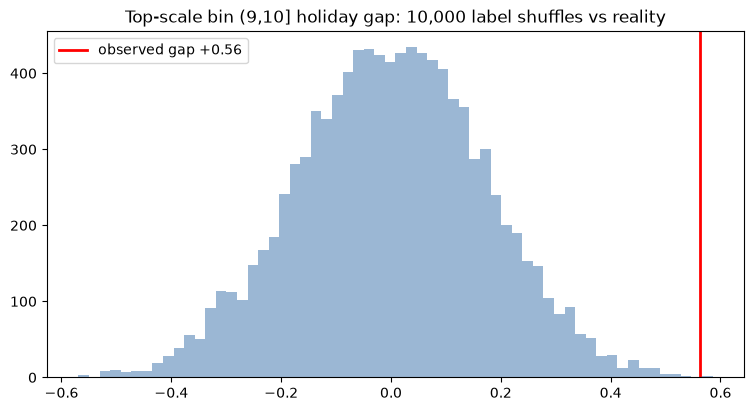

share of shuffles >= observed: 0.00029997000299970003


In [15]:
top_bin = df["Scale_Bin"].cat.categories[-1]   # Interval(9, 10] — compare with the Interval, not a string
sub  = df[df["Scale_Bin"] == top_bin]
x1   = sub.loc[sub["Holiday"], "log_revenue"].values
x0   = sub.loc[~sub["Holiday"], "log_revenue"].values
pool = np.concatenate([x1, x0]); n1 = len(x1)
obs  = x1.mean() - x0.mean()
luck = np.array([(lambda p: p[:n1].mean() - p[n1:].mean())(rng.permutation(pool))
                 for _ in range(10_000)])
plt.figure(figsize=(9, 4.5))
plt.hist(luck, bins=60, color="#9bb7d4")
plt.axvline(obs, color="red", lw=2, label=f"observed gap {obs:+.2f}")
plt.title("Top-scale bin (9,10] holiday gap: 10,000 label shuffles vs reality"); plt.legend(); plt.show()
print("share of shuffles >= observed:", (np.sum(luck >= obs) + 1) / 10_001)

**📌 Inference (Step 8):** The shuffle grid gave us the H1 and H2 verdicts on the same scale bins the regression and hypothesis notebooks use: the red observed line escapes the pile of 10,000 shuffles only for festival films in the top two bins ((8,9] +0.21, p = 0.023; (9,10] +0.56, about 76% more revenue, p = 0.001) and for franchise films in (7,8] (+0.43, p = 0.045), while every bin below (7,8] stays deep inside the pile. The grey panels are also a finding: franchise and remake films barely exist below scale 7, so safe bet status is only granted at scale.

**📌 Inference (Step 8, per scale bin):** Bin by bin the festival effect is absent through (1,2]–(7,8] (all gaps between -0.21 and +0.25, p ≥ 0.07) and appears only at the top: (8,9] +0.21 (p = 0.023) and (9,10] +0.56 (p = 0.001, about 76% more money). Franchise is testable only in the top three bins and significant in one ((7,8] +0.43, p = 0.045); remake is significant in (7,8] (+0.53, p = 0.005) and (8,9] (+0.22, p = 0.047) and flips sign at the very top ((9,10] -0.25, p = 0.92). On the whole-sample returns scale the same dissolving shows up in the ROI ladders of 5.HypothesisTesting.ipynb (raw -> scale-adjusted -> full, HC3): holiday +0.23 -> +0.07 -> +0.06 (never significant once scale is held), franchise +1.38 -> +0.62 -> +0.67 and remake +0.96 -> +0.24 -> +0.30, both keeping a significant remainder. The scale-bin tests here use log revenue, the ladders there use ROI, and both point the same way: the raw premiums are mostly scale, and what survives is a franchise/remake premium, not a festival one.

## STEP 8c — Does money buy ROI? (stratified label shuffle)


observed ROI gap (high- minus low-spender) = +1.0165
stratified shuffle p (two-sided) = 0.4043
luck pile: mean 1.0115 | sd 0.0193
Scale_Bin
(1, 2]       NaN
(2, 3]       NaN
(3, 4]    -0.156
(4, 5]    -0.172
(5, 6]    -0.192
(6, 7]     0.085
(7, 8]    -0.565
(8, 9]       NaN
(9, 10]      NaN


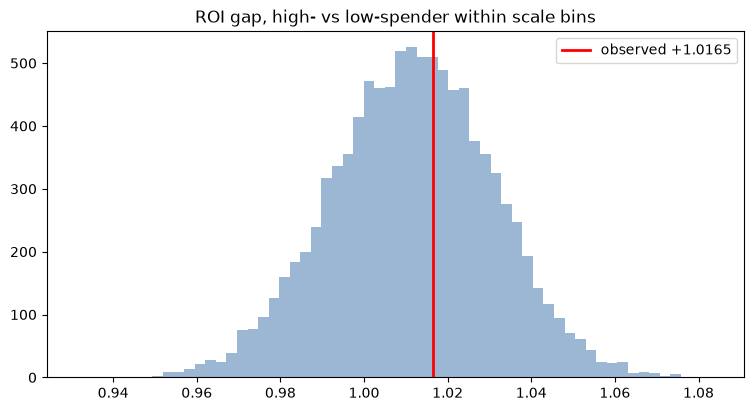

In [16]:
df['Budget_Above_Median'] = (df['Budget'] > df['Budget'].median()).astype(int)  # Scale_Bin already defined in Step 8

def perm_diff(data, group_col, value_col, strata_col, n_perm=10_000, seed=42):
    vals   = data[value_col].to_numpy(float)
    labels = data[group_col].to_numpy(int)
    strata_idx = [g.index.to_numpy() for _, g in data.groupby(strata_col)]
    obs = vals[labels == 1].mean() - vals[labels == 0].mean()
    r = np.random.default_rng(seed)
    null = np.empty(n_perm)
    for i in range(n_perm):
        plab = labels.copy()
        for idx in strata_idx:
            plab[idx] = r.permutation(labels[idx])
        null[i] = vals[plab == 1].mean() - vals[plab == 0].mean()
    p = (np.sum(np.abs(null) >= abs(obs)) + 1) / (n_perm + 1)
    return obs, null, p

budget_obs, budget_null, budget_p = perm_diff(df, 'Budget_Above_Median', 'ROI', 'Scale_Bin')
print(f"observed ROI gap (high- minus low-spender) = {budget_obs:+.4f}")
print(f"stratified shuffle p (two-sided) = {budget_p:.4f}")
print("luck pile: mean", round(budget_null.mean(), 4), "| sd", round(budget_null.std(), 4))

gaps = df.groupby('Scale_Bin').apply(
    lambda g: g.loc[g.Budget_Above_Median == 1, 'ROI'].mean() - g.loc[g.Budget_Above_Median == 0, 'ROI'].mean(),
    include_groups=False)
print(gaps.round(3).to_string())

plt.figure(figsize=(9, 4.5))
plt.hist(budget_null, bins=60, color="#9bb7d4")
plt.axvline(budget_obs, color="red", lw=2, label=f"observed {budget_obs:+.4f}")
plt.title("ROI gap, high- vs low-spender within scale bins"); plt.legend(); plt.show()

**📌 Inference (Step 8c):** In the stratified test we split films at the median budget inside scale bins and shuffled within each bin: the high spenders' ROI advantage of +1.02 sits exactly at the centre of its own luck pile (p = 0.40, two sided), so spending more does not improve returns at similar scale. Four bins were NaN because the median split puts every film on one side there. This matches our regression and mediation results: budget buys screens and reach, and reach buys revenue, not better returns per rupee.